In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
import os


In [9]:
# I downloaded the dataset instead of using the path, so the folder containing ALL the images is on my computer

In [10]:
# Part 3: Count Images in Each Class

def count_images_in_classes(folder_name):
    class_counts = {}
    
    # Loop through each item in the folder 
    for class_name in os.listdir(folder_name):
        class_path = os.path.join(folder_name, class_name)
        
        # Make sure subfolder exists
        if os.path.isdir(class_path):
            # Count the files inside that class folder
            num_images = len(os.listdir(class_path))
            class_counts[class_name] = num_images
            
    return class_counts

train_counts = count_images_in_classes("Vegetable Images/train")
test_counts = count_images_in_classes("Vegetable Images/test")
val_counts = count_images_in_classes("Vegetable Images/validation")

print("Train folder:", train_counts)
print("\nTest folder:", test_counts)
print("\nValidation folder:", val_counts)

# Summary
"""
Train: 1000 of EACH class
Test: 200 of EACH class
Validation: 200 of EACH class
"""

Train folder: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Test folder: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation folder: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


'\nTrain: 1000 of EACH class\nTest: 200 of EACH class\nValidation: 200 of EACH class\n'

In [11]:
# Part 4: Create a Summary DataFrame

# Create the three individual DataFrames
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

# 2. Merge them into one final DataFrame
df = pd.merge(train_df, test_df, on="Vegetable")
df = pd.merge(df, val_df, on="Vegetable")

# 3. Display the final DataFrame
print(df)
# Or simply write `summary_df` at the end of a Jupyter Notebook cell for a nice table view

       Vegetable  Train Count  Test Count  Validation Count
0           Bean         1000         200               200
1   Bitter_Gourd         1000         200               200
2   Bottle_Gourd         1000         200               200
3        Brinjal         1000         200               200
4       Broccoli         1000         200               200
5        Cabbage         1000         200               200
6       Capsicum         1000         200               200
7         Carrot         1000         200               200
8    Cauliflower         1000         200               200
9       Cucumber         1000         200               200
10        Papaya         1000         200               200
11        Potato         1000         200               200
12       Pumpkin         1000         200               200
13        Radish         1000         200               200
14        Tomato         1000         200               200


In [12]:
df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


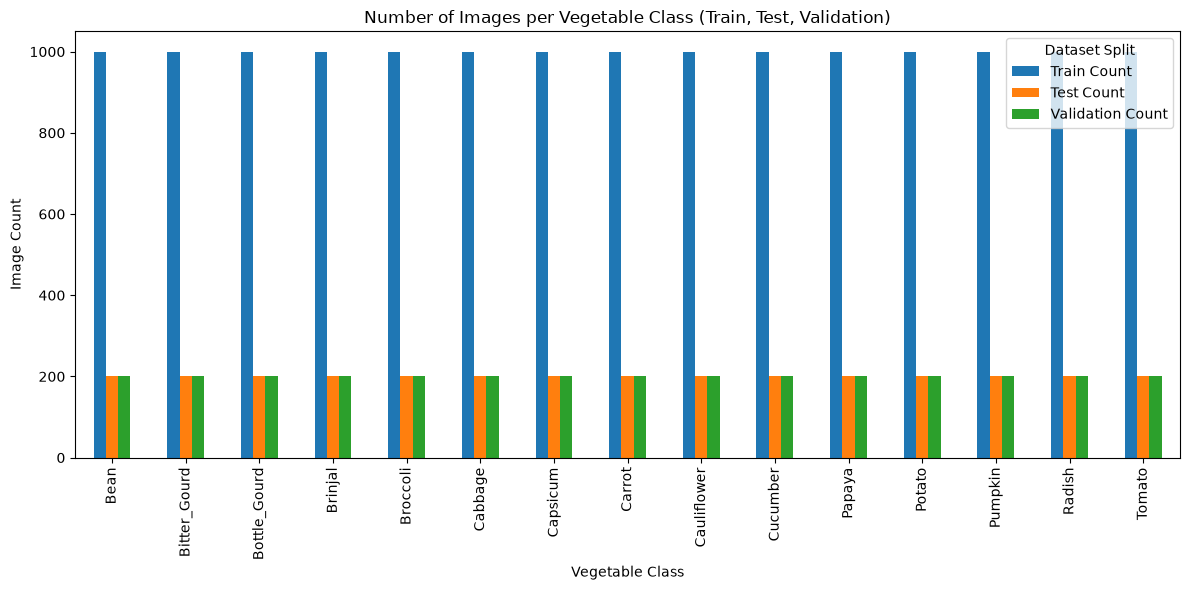

'Yes, the dataset is balanced, as each vegetable has 1000 images for training, 200 images for testing, and 200 images for validation.So no bias towards any classp'

In [13]:
# Part 5: Visualize Class Distribution
df.plot(
    x="Vegetable",
    y=["Train Count", "Test Count", "Validation Count"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("Number of Images per Vegetable Class (Train, Test, Validation)")
plt.xlabel("Vegetable Class")
plt.ylabel("Image Count")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

"Yes, the dataset is balanced, as each vegetable has 1000 images for training, 200 images for testing, and 200 images for validation.So no bias towards any classp"

In [ ]:
# Part 6: Image Preprocessing and Augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Training generator with rescaling, augmentation, and validation split
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

# Validation generator with ONLY rescaling and validation split (no augmentation)
val_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=0.2
)

In [16]:
# Part 7: Load Images Using flow_from_directory
train_dir = "Vegetable Images/train"

train_ds = train_datagen.flow_from_directory(
    directory=train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="training",
    seed=42
)

val_ds = val_datagen.flow_from_directory(
    directory=train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

print("Class indices:", train_ds.class_indices)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Class indices: {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


In [ ]:
# Part 8: Building the CNN Model
from tensorflow.keras import layers, models,Sequential

model = Sequential()
# Conv block 1
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(layers.MaxPooling2D(pool_size=(2, 2)))
# Conv block 2
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPool2D(pool_size=(2,2)))
# Conv block 3
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPool2D(pool_size=(2,2)))

# Fully connected layers:
model.add(layers.Flatten())
model.add(layers.Dense(512,activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(15, activation='softmax'))

model.summary()

c:\Users\moham\Downloads\My Learning\Ai&ML- Route\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Part 9: Compile the Model & Print Summary
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
"""
1. **Number of Convolutional Layers:**
   The model has **3 `Conv2D` layers** (with 32, 64, and 128 filters of size `3x3`), which extract features from simple edges/colors.

2. **Purpose of Pooling Layers:**
   The `MaxPooling2D(2, 2)` layers to decrease the features

3. **Purpose of Dropout:**
   `Dropout(0.5)` randomly turns off 50% of the neurons in the Dense layer during each training step. This prevents the network from relying too heavily on specific neurons and reduces **overfitting**.

4. **Why Softmax is Used in the Output Layer:**
   Since this is a multi-class classification** problem with 15 classes, `softmax` converts the 15 raw output scores into a probability distribution (values between `0` and `1` that sum to `1.0`), so the class with the highest probability is chosen as the prediction.
"""

In [24]:
# Part 10: Train the Model
from tensorflow.keras.callbacks import EarlyStopping

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

"""
Did only 5 epochs as model takes too long to train.
"""

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 371s 989ms/step - accuracy: 0.5547 - loss: 1.3152 - val_accuracy: 0.7697 - val_loss: 0.7149
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 166s 443ms/step - accuracy: 0.7087 - loss: 0.8960 - val_accuracy: 0.8403 - val_loss: 0.5299
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 170s 453ms/step - accuracy: 0.7768 - loss: 0.6838 - val_accuracy: 0.8763 - val_loss: 0.4100
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 162s 432ms/step - accuracy: 0.8017 - loss: 0.6062 - val_accuracy: 0.8727 - val_loss: 0.3725
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 165s 441ms/step - accuracy: 0.8347 - loss: 0.5195 - val_accuracy: 0.9277 - val_loss: 0.2479


'\nDid only 5 as\n'

In [ ]:
# Part 11: Evaluate the Model
train_losses = history.history["loss"]
val_losses = history.history["val_loss"]
train_accs = history.history["accuracy"]
val_accs = history.history["val_accuracy"]

print(f"Training Accuracy:   {train_accs[-1] * 100:.2f}%")
print(f"Validation Accuracy: {val_accs[-1] * 100:.2f}%")
print(f"Training Loss:       {train_losses[-1]:.4f}")
print(f"Validation Loss:     {val_losses[-1]:.4f}")

"""
- Training Accuracy (83.47%) is < than Validation Accuracy (92.77%), and Validation Loss (0.2479) is < than Training Loss (0.5195).
- This tells us there is NO overfitting—the model is generalizing very well to unseen images.
"""

Training Accuracy:   83.47%
Validation Accuracy: 92.77%
Training Loss:       0.5195
Validation Loss:     0.2479


'\nIs there a large difference between training accuracy and validation accuracy? What does this tell you about overfitting?\n- Training Accuracy (83.47%) is actually LOWER than Validation Accuracy (92.77%), and Validation Loss (0.2479) is lower than Training Loss (0.5195).\n- This tells us there is NO overfitting—the model is generalizing very well to unseen images.\n- Validation accuracy is higher because random Data Augmentation and Dropout(0.5) make the training images harder during training, while validation is evaluated on clean, unaugmented images with all neurons active.\n'

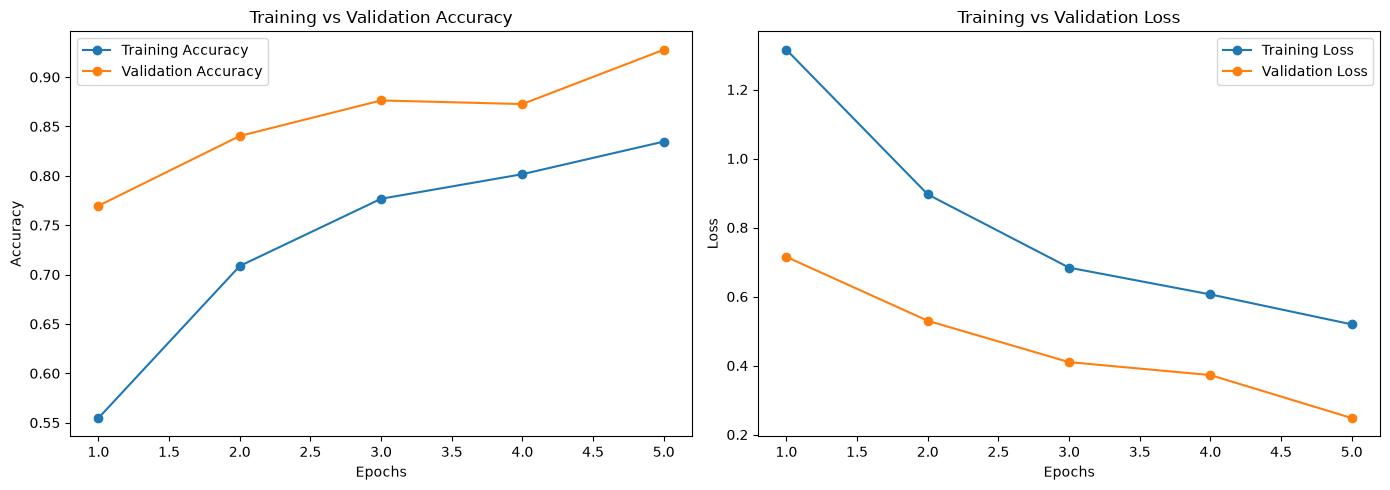

In [27]:
# Part 12: Plot Accuracy and Loss Curves
epochs_range = range(1, len(history.history['accuracy']) + 1) # creates the list of epoch numbers

plt.figure(figsize=(14, 5))

# Plot 1: Training vs Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot 2: Training vs Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()